In [2]:
# import numpy as np
import pandas as pd
import matplotlib.gridspec as gridspec

import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvas
from scipy.spatial import distance
import random as rand
import pickle
from scipy import stats
import time


# allow us to re-use the framework from the src directory
import sys, os
sys.path.append(os.path.abspath(os.path.join('../')))

import max_ent.examples.grid_9_by_9 as G
from max_ent.utility.support import *
from max_ent.gridworld import Directions


rand.seed(123)
np.random.seed(123)

In [3]:

'''label='length'
list_df = [df3[label],df4[label]]
list_mean=[(np.mean(x)+np.std(x))*1.1 for x in list_df]

print(np.max(list_mean))
'''
'''def min_max(label, df, df2, df3, df4, df7):
    list_df = [df[label],df2[label],df3[label],df4[label],df7[label]]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label'''

def min_max(label, df):
    list_df = df[label]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    #print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label

In [4]:
def plot_subtype(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna = False):
    
    print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(60, 15))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) & ((df['type']=='SOFAI w/ S1 ra=0.0') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.25') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')
        
        # real subplot #2
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.5') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.75') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], ci=None, hue=hue,markers=True, dashes=False)
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=1.0') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])

    plt.savefig(filename+'.pdf')
    plt.show()

def plot_type(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna=False):
         
    ci=None
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(60, 30))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)
    #print(df['type'])

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.25')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.5')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.75')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.75'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=1.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=1.0'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')

    plt.savefig(filename+'.pdf')
    plt.show()



In [5]:
def f(count_stat):
    Z = []

    for x in range(9):
        temp_grid = []
        for y in range(9):
            #print(f"({x},{y})")
            temp_grid.append(np.sum(count_stat[0][y][8-x]))
            
        #print(temp_grid)
        Z.append(temp_grid)
    return np.array(Z)

In [6]:
def plot_results(df, x, y, min_label, max_label, bootstrap = 0):
    
    fig=plt.figure(figsize=(12, 7))
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    temp_df = df.loc[(df['type']!="S1 noMyopic")&(df['type']!="const")&(df['type']!="nominal")& (df['type']!="S1 Myopic") & (df['type']!="S2")& (df['traj_n']>=bootstrap)]
    #print("Prima")
    #g=sns.lineplot(x=x, y=y, data=df, hue="type",markers=True, dashes=False)
    g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);
    #print("Dopo")
    #g.set_xticklabels([f"({(i)/10:0.1f}, {1 - (i)/10:0.1f})" for i in range(11)])
    
    constrained_line = np.mean(df.loc[(df['type']=="const")][y])
    nominal_line = np.mean(df.loc[(df['type']=="nominal")][y])
    #print(f"constrained_line: {constrained_line} {y}")
    #print(f"nominal_line: {nominal_line} {y}")
    #s1_line = np.mean(df.loc[(df['type']=="s1")& (df['traj_n']>=bootstrap)][y])
    s2_line = np.mean(df.loc[(df['type']=="S2")& (df['traj_n']>=0)][y])
    #mixed_line = np.median(temp_df.loc[(temp_df['type']=="mixed")& (temp_df['traj_n']>=bootstrap)][y])
    #s1nb_line_noMyopic = np.mean(df.loc[(df['type']=="S1 noMyopic")& (df['traj_n']>=0)][y])
    #s1nb_line_Myopic = np.mean(df.loc[(df['type']=="S1 Myopic")& (df['traj_n']>=0)][y])
    
    #print(f"s2: {s2_line} s1:{s1nb_line}")
    
    g.axhline(constrained_line, color='r', linestyle='--', label="RL Constrained")
    g.axhline(nominal_line, color='b', linestyle='--', label="RL Nominal")
    #g.axhline(s1_line, color='b', linestyle='--', label="S1")
    #g.axhline(mixed_line, color='g', linestyle='--', label="Mixed")
    #g.axhline(s1nb_line_noMyopic, color='b', linestyle='-.', label="S1 no Myopic")
    #g.axhline(s1nb_line_Myopic, color='black', linestyle='-.', label="S1 Myopic")
    g.axhline(s2_line, color='g', linestyle='-.', label="S2")
    #g.set_ylim([min_label, max_label])

    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    #plt.title(label=y+" varying "+x)
    
    '''h, l = g.get_legend_handles_labels()
    labels=["S1", "S2","SOFAI 10","SOFAI 01","SOFAI 02"]
    g.legend(h, labels)'''
    plt.legend()
    plt.grid(alpha=0.3)
    #g.set_xticks(range(11)) # <--- set the ticks first

    #plt.xlabel("W(Nominal, Constraints)")
    #plt.ylabel("Avg JS dist")
    plt.show()
    #fig.savefig(os.path.join("./", f"{y}_varying_{x}.png"), bbox_inches = 'tight')
    fig.savefig(os.path.join("./", f"{y}.pdf"), bbox_inches = 'tight')

In [7]:
def runSOFAI(n, c, mca_01_myopic, threshold1, threshold2, threshold3, threshold4, threshold5, ra, n_trajectories, trial, mca_s2, title, constraints, n_grid=None):
    s1_ra0 = System1Solver(myopic=False, ra=ra)
    if mca_01_myopic is None: 
        mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, s2=mca_s2.s2, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1)
    else:
        mca_01_myopic.setGrid(grid=n, constraints=c)  
        
    demo_mca_01_myopic = mca_01_myopic.generate_trajectories(n_trajectories, discard_not_feasable=False)
    #temp_matrix_mca_01_myopic = count_states(demo_mca_01_myopic.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
    temp_dict=build_dict(type_mca=title, agent=mca_01_myopic, t3= threshold3, demo = demo_mca_01_myopic, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
    #f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
    #df = pd.concat([df, temp_dict])

    temp_jsdiv = {}
    temp_jsdiv['t3'] = threshold3
    temp_jsdiv['t4'] = threshold4
    temp_jsdiv['jsdiv'] = js_divergence((mca_s2.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_s2.modelSelf.ntra_per_transition + 1E-10), (mca_01_myopic.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_01_myopic.modelSelf.ntra_per_transition + 1E-10))
    temp_jsdiv['type'] = title
    temp_jsdiv = pd.DataFrame(data=temp_jsdiv, index=[0])
    
    return mca_01_myopic, temp_dict, temp_jsdiv, demo_mca_01_myopic

In [24]:
n_grids = 3

n_trials = 200 #

n_trajectories = 1
goal = 40

bootstrap = 0
n_constraints = 27
n_actions = 4

threshold1 = 100 # 
threshold2 = 0.95 #0.95 # THIS REMOVE SECOND CONDITION
#threshold3 = 0.1
#list_threshold3 = [0.1, 0.3, 0.6, 0.9] # try with 0.9 or 1.0 / myopic and non-myopic S1
list_threshold3 = [0.3,] # try with 0.9 or 1.0 / myopic and non-myopic S1
threshold4 = 0 # 

p_slip = 0.1

In [25]:

df = pd.DataFrame()
df2 = pd.DataFrame()
df3 = pd.DataFrame()
df4 = pd.DataFrame()
df7 = pd.DataFrame()

In [26]:

time_tot = int(round(time.time() * 1000))

df = pd.DataFrame()
js_div = pd.DataFrame()
mca = []
size = 9

mca_1 = None
mca_2 = None
mca_3 = None
mca_4 = None
mca_5 = None

list_initial_state = [0,1,2,3,4,5,6,7,8,9,18,27,36,45,54,63,72,73,74,75,76,77,78,79,80,17,26,35,44,53,62,71]

for n_grid in range(n_grids):

    resetModelSelf = True
    mca_agents = [None for i in range(20)]

    blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)
    constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}

    

    #list_available = [x for x in range(size ** 2)]
    list_available = np.array(list_initial_state)
    list_available = np.setdiff1d(list_available, blue)
    list_available = np.setdiff1d(list_available, green)
    list_available = np.setdiff1d(list_available, cs)
    list_available = np.setdiff1d(list_available, [goal])

    demo_list =[]
    
    #generate nomminal 
    time_exp = int(round(time.time() * 1000))
    n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 
    temp_matrix = count_states(demo_n.trajectories, n_cfg.mdp, n, constraints)
    '''temp_dict=build_dict(temp_matrix, type_mca='nominal')
    temp_dict['time'] = time_exp / n_trajectories
    df = pd.concat([df, temp_dict])'''

    Z_distr = f(temp_matrix)
    Z_distr = np.array(Z_distr)
    Z_distr = Z_distr + 1E-3
    Z_distr[8-int(start/9)][int(start%9)]=0
    Z_distr[8-int(goal/9)][int(goal%9)] = 0

    #plt.imshow(Z_distr/np.sum(Z_distr), cmap='hot', interpolation='nearest')
    #plt.show()

    #Z_distr/np.sum(Z_distr)
    distr = np.array(Z_distr/np.sum(Z_distr))

    new_distr = []
    for idistr in range(len(distr)):
        new_distr.append(distr[len(distr)-idistr-1])

    new_distr = np.array(new_distr)


    ##cs = np.random.choice(np.arange(0,81), replace=False, p = new_distr.flatten(), size = n_constraints)
    #constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}
    print(f"Start: {start} Goal: {goal} \nConstraints: {constraints}")
    #exit()

    #generate constrained grid
    cc = [1, 2]
    time_exp = int(round(time.time() * 1000))
    c, c_cfg, demo_c, f2 = create_world('Constrained', blue, green, cs, ca, cc, start=start, goal=goal, check=True, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 

    #COMPUTE STATISTICS FOR NOMINAL
    temp_matrix = count_states(demo_n.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='nominal', demo = demo_n, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    #COMPUTE STATISTICS FOR CONSTRAINED
    temp_matrix = count_states(demo_c.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='const', demo = demo_c, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    for trial in range(n_trials):
        #print(f"Iteration {trial}")
        #generate constraints

        #start = np.random.choice(list_available)
        #start = np.random.choice(list_initial_state)
        '''generate = True
        while generate:
            # generate start state from the list of non-constrained states
            start = np.random.choice(list_available)
            start_x = start % size
            start_y = start // size

            goal_x = goal % size
            goal_y = goal // size

            if abs(start_x-goal_x) > 3 or abs(start_y-goal_y) > 3:
                generate = False'''

        '''blue = [21,  9, 59,  1,  0, 20]
        green = [42, 18, 76, 41, 23, 30]
        cs = [63, 74, 13, 39, 48, 38]
        ca = [Directions.DOWN_LEFT, Directions.UP_LEFT]'''
        ##start =7
        ##goal = 65


        if resetModelSelf: 
            mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
        else:
            mca_s2.setGrid(grid=n, constraints=c)

        demo_mca_s2 = mca_s2.generate_trajectories(n_trajectories)
        #temp_matrix_mca_s2 = count_states(demo_mca_s2.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
        temp_dict=build_dict( type_mca='S2', agent=mca_s2 , demo = demo_mca_s2, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
        #f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
        df = pd.concat([df, temp_dict])

        for i_threshold3 in range(len(list_threshold3)):

            print(f"\n ************** Threshold {i_threshold3}: Trial {trial} grid {n_grid} ******************")
            threshold3 = list_threshold3[i_threshold3]

            '''mca_agents[i_threshold3 * 5 + 0], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 0], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.0', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 1], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 1], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.25', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 2], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 2], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.5', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 3], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 3], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.75', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])'''

            mca_agents[i_threshold3 * 5 + 4], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 4], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=1.0', constraints= constraints)
            if i_threshold3 == len(list_threshold3)-1: demo_list = demo_list + demo.trajectories
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            if ((trial+1) %25 ==0): 
                r=mca_agents[i_threshold3 * 5 + 4].reflect(p=0.2)
                print(f"Temperature: {mca_agents[i_threshold3 * 5 + 4].temperature}")

            resetModelSelf = False

        time_exp = int(round(time.time() * 1000))
        start = np.random.choice(np.setdiff1d(list_initial_state, cs))
        n.start[0] = start
        print(f"start {start}")


'''f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
#f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_Myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_noMyopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
'''
time_tot = int(round(time.time() * 1000)) - time_tot
print(f"Total time: {time_tot}")


[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]
Start: 36 Goal: 40 
Constraints: {'blue': [], 'green': [], 'cs': array([ 3,  0, 66, 48, 64, 67, 80, 42, 14, 76, 33,  2, 65, 53, 60, 39, 32,
       37, 57, 18, 74,  5,  7, 34,  9, 69,  6]), 'ca': [UP_LEFT, DOWN_RIGHT, RIGHT, UP]}
[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]


/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:104: RuntimeWarning: invalid value encountered in long_scalars
  dict_mca['avg_time'] = time_s1 / usage_s1
/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:106: RuntimeWarning: invalid value encountered in double_scalars
  dict_mca['avg_reward'] = reward_s1 / usage_s1



 ************** Threshold 0: Trial 0 grid 0 ******************
start 45

 ************** Threshold 0: Trial 1 grid 0 ******************
start 63

 ************** Threshold 0: Trial 2 grid 0 ******************
start 4

 ************** Threshold 0: Trial 3 grid 0 ******************
start 78

 ************** Threshold 0: Trial 4 grid 0 ******************
start 54


/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:178: RuntimeWarning: divide by zero encountered in double_scalars
  action_thresholds[1] = expected_avg_reward / current_reward
/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:367: RuntimeWarning: invalid value encountered in double_scalars
  x = np.abs(current_length - expected_avg_length) / max_diff_len



 ************** Threshold 0: Trial 5 grid 0 ******************
start 26

 ************** Threshold 0: Trial 6 grid 0 ******************
start 54

 ************** Threshold 0: Trial 7 grid 0 ******************
start 79

 ************** Threshold 0: Trial 8 grid 0 ******************
start 45

 ************** Threshold 0: Trial 9 grid 0 ******************
start 1

 ************** Threshold 0: Trial 10 grid 0 ******************
start 62

 ************** Threshold 0: Trial 11 grid 0 ******************
start 27

 ************** Threshold 0: Trial 12 grid 0 ******************
start 62

 ************** Threshold 0: Trial 13 grid 0 ******************


...

/Users/aloreggia/Documents/GitHub/wmca/mc/self.py:459: RuntimeWarning: invalid value encountered in double_scalars
  return np.sum(self.s1_wrong_list[-201:-1]) / len(self.s1_wrong_list[-201:-1])


start 27

 ************** Threshold 0: Trial 2 grid 1 ******************
start 80

 ************** Threshold 0: Trial 3 grid 1 ******************
start 53

 ************** Threshold 0: Trial 4 grid 1 ******************
start 80

 ************** Threshold 0: Trial 5 grid 1 ******************
start 7

 ************** Threshold 0: Trial 6 grid 1 ******************
start 72

 ************** Threshold 0: Trial 7 grid 1 ******************
start 78

 ************** Threshold 0: Trial 8 grid 1 ******************
start 78

 ************** Threshold 0: Trial 9 grid 1 ******************
start 54

 ************** Threshold 0: Trial 10 grid 1 ******************
start 77

 ************** Threshold 0: Trial 11 grid 1 ******************
start 78

 ************** Threshold 0: Trial 12 grid 1 ******************
start 54

 ************** Threshold 0: Trial 13 grid 1 ******************
start 7

 ************** Threshold 0: Trial 14 grid 1 ******************
start 54

 ************** Threshold 0: Trial 15 

start 79

 ************** Threshold 0: Trial 106 grid 1 ******************
start 2

 ************** Threshold 0: Trial 107 grid 1 ******************
start 44

 ************** Threshold 0: Trial 108 grid 1 ******************
start 5

 ************** Threshold 0: Trial 109 grid 1 ******************
start 80

 ************** Threshold 0: Trial 110 grid 1 ******************
start 36

 ************** Threshold 0: Trial 111 grid 1 ******************
start 53

 ************** Threshold 0: Trial 112 grid 1 ******************
start 2

 ************** Threshold 0: Trial 113 grid 1 ******************
start 77

 ************** Threshold 0: Trial 114 grid 1 ******************
start 26

 ************** Threshold 0: Trial 115 grid 1 ******************
start 63

 ************** Threshold 0: Trial 116 grid 1 ******************
start 72

 ************** Threshold 0: Trial 117 grid 1 ******************
start 63

 ************** Threshold 0: Trial 118 grid 1 ******************
start 5

 ************** Thr

start 77

 ************** Threshold 0: Trial 3 grid 2 ******************
start 26

 ************** Threshold 0: Trial 4 grid 2 ******************
start 36

 ************** Threshold 0: Trial 5 grid 2 ******************
start 54

 ************** Threshold 0: Trial 6 grid 2 ******************
start 76

 ************** Threshold 0: Trial 7 grid 2 ******************
start 75

 ************** Threshold 0: Trial 8 grid 2 ******************
start 54

 ************** Threshold 0: Trial 9 grid 2 ******************
start 44

 ************** Threshold 0: Trial 10 grid 2 ******************
start 75

 ************** Threshold 0: Trial 11 grid 2 ******************
start 26

 ************** Threshold 0: Trial 12 grid 2 ******************
start 63

 ************** Threshold 0: Trial 13 grid 2 ******************
start 6

 ************** Threshold 0: Trial 14 grid 2 ******************
start 7

 ************** Threshold 0: Trial 15 grid 2 ******************
start 26

 ************** Threshold 0: Trial 16

start 75

 ************** Threshold 0: Trial 110 grid 2 ******************
start 1

 ************** Threshold 0: Trial 111 grid 2 ******************
start 76

 ************** Threshold 0: Trial 112 grid 2 ******************
start 54

 ************** Threshold 0: Trial 113 grid 2 ******************
start 54

 ************** Threshold 0: Trial 114 grid 2 ******************
start 3

 ************** Threshold 0: Trial 115 grid 2 ******************
start 26

 ************** Threshold 0: Trial 116 grid 2 ******************
start 9

 ************** Threshold 0: Trial 117 grid 2 ******************
start 76

 ************** Threshold 0: Trial 118 grid 2 ******************
start 76

 ************** Threshold 0: Trial 119 grid 2 ******************
start 26

 ************** Threshold 0: Trial 120 grid 2 ******************
start 4

 ************** Threshold 0: Trial 121 grid 2 ******************
start 53

 ************** Threshold 0: Trial 122 grid 2 ******************
start 17

 ************** Thr

In [ ]:
temp_demo = Demonstration(demo_list, demo.policy)
#df.to_csv("dati_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")
#js_div.to_csv("jsdiv_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")

In [ ]:
G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [ ]:
temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==0.9) &  ((df['type']=='SOFAI w/ S1') )  ]

In [ ]:
#plt.plot(temp_df.loc[temp_df['sub_type']=='s1']['usage'])

In [ ]:
#x='traj_n'
#y='perc_usage'

#g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue="sub_type",markers=True, dashes=False)

[0, None]


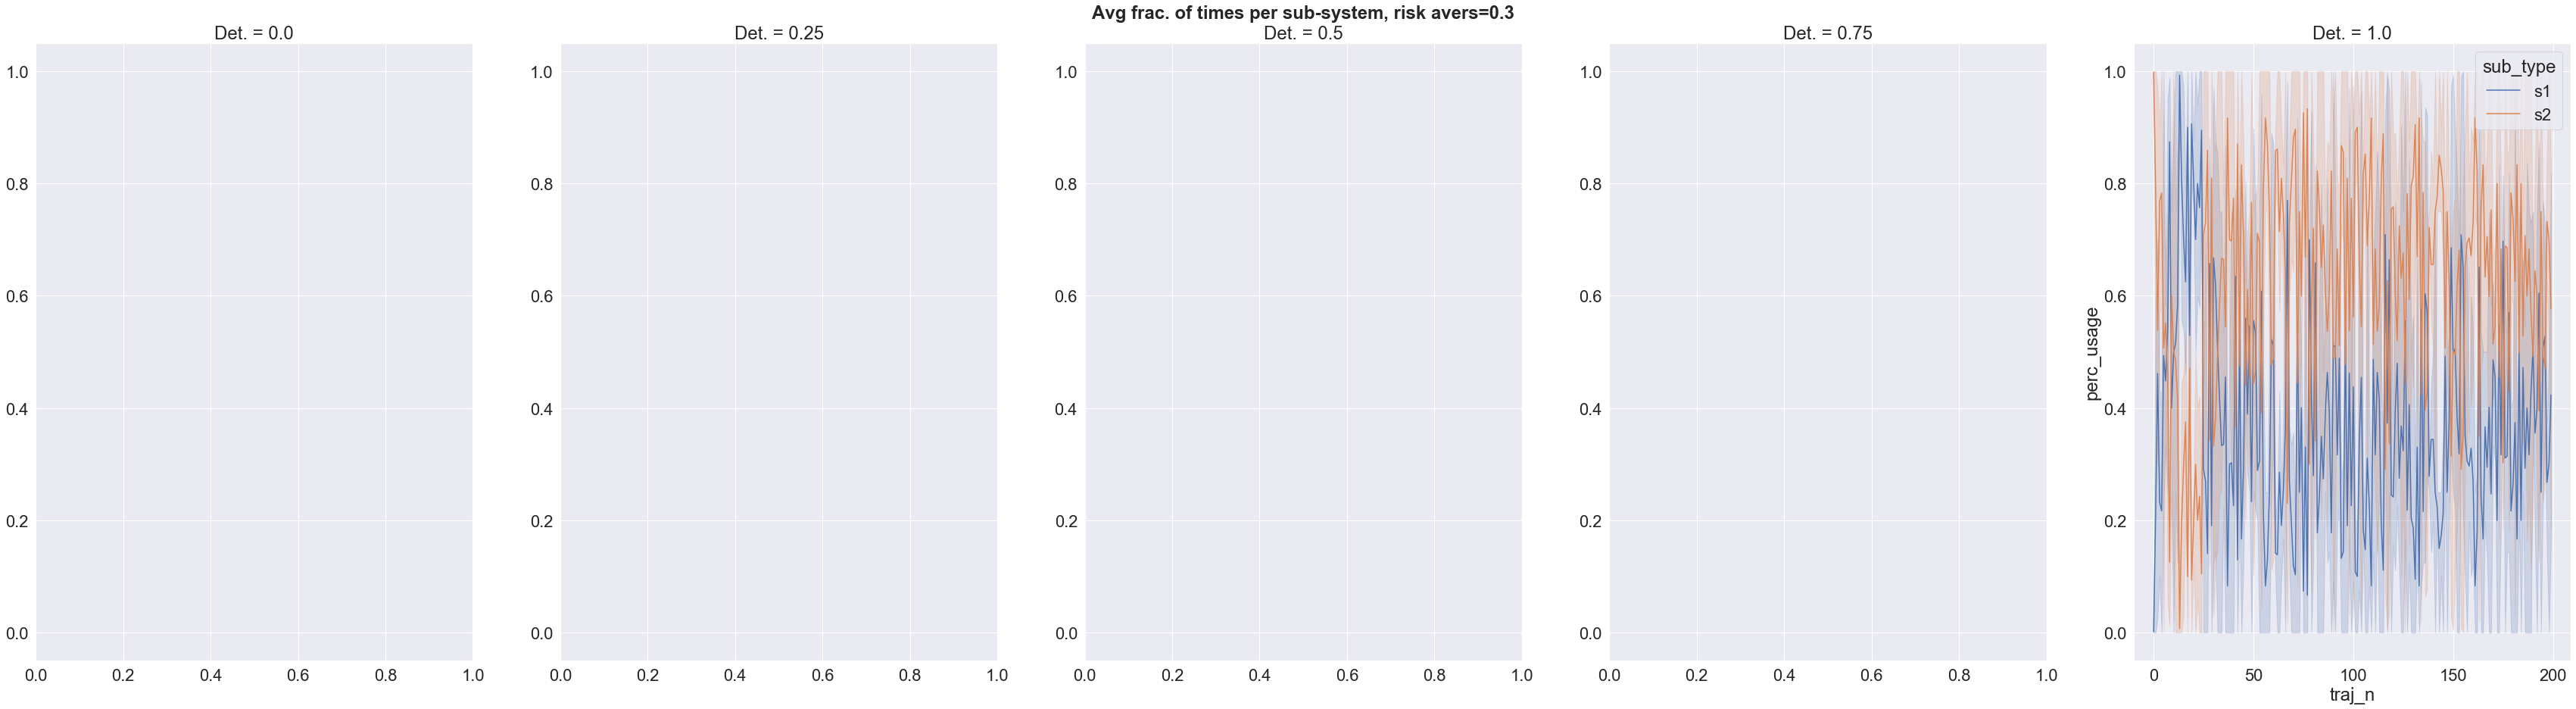

In [27]:
x='traj_n'
y='perc_usage'
#y='avg_reward'
#y='avg_time'
filename = y+'_risk'
title="Avg frac. of times per sub-system, risk avers="

plot_subtype(x,y,df,"sub_type",title,filename, list_threshold3=list_threshold3)

In [ ]:
mca_agents[4].__dict__.keys()

In [ ]:
x='traj_n'
y='avg_reward'
#y='avg_time'
filename = y+'_risk_'
title="Avg reward per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True)


[0, 40]


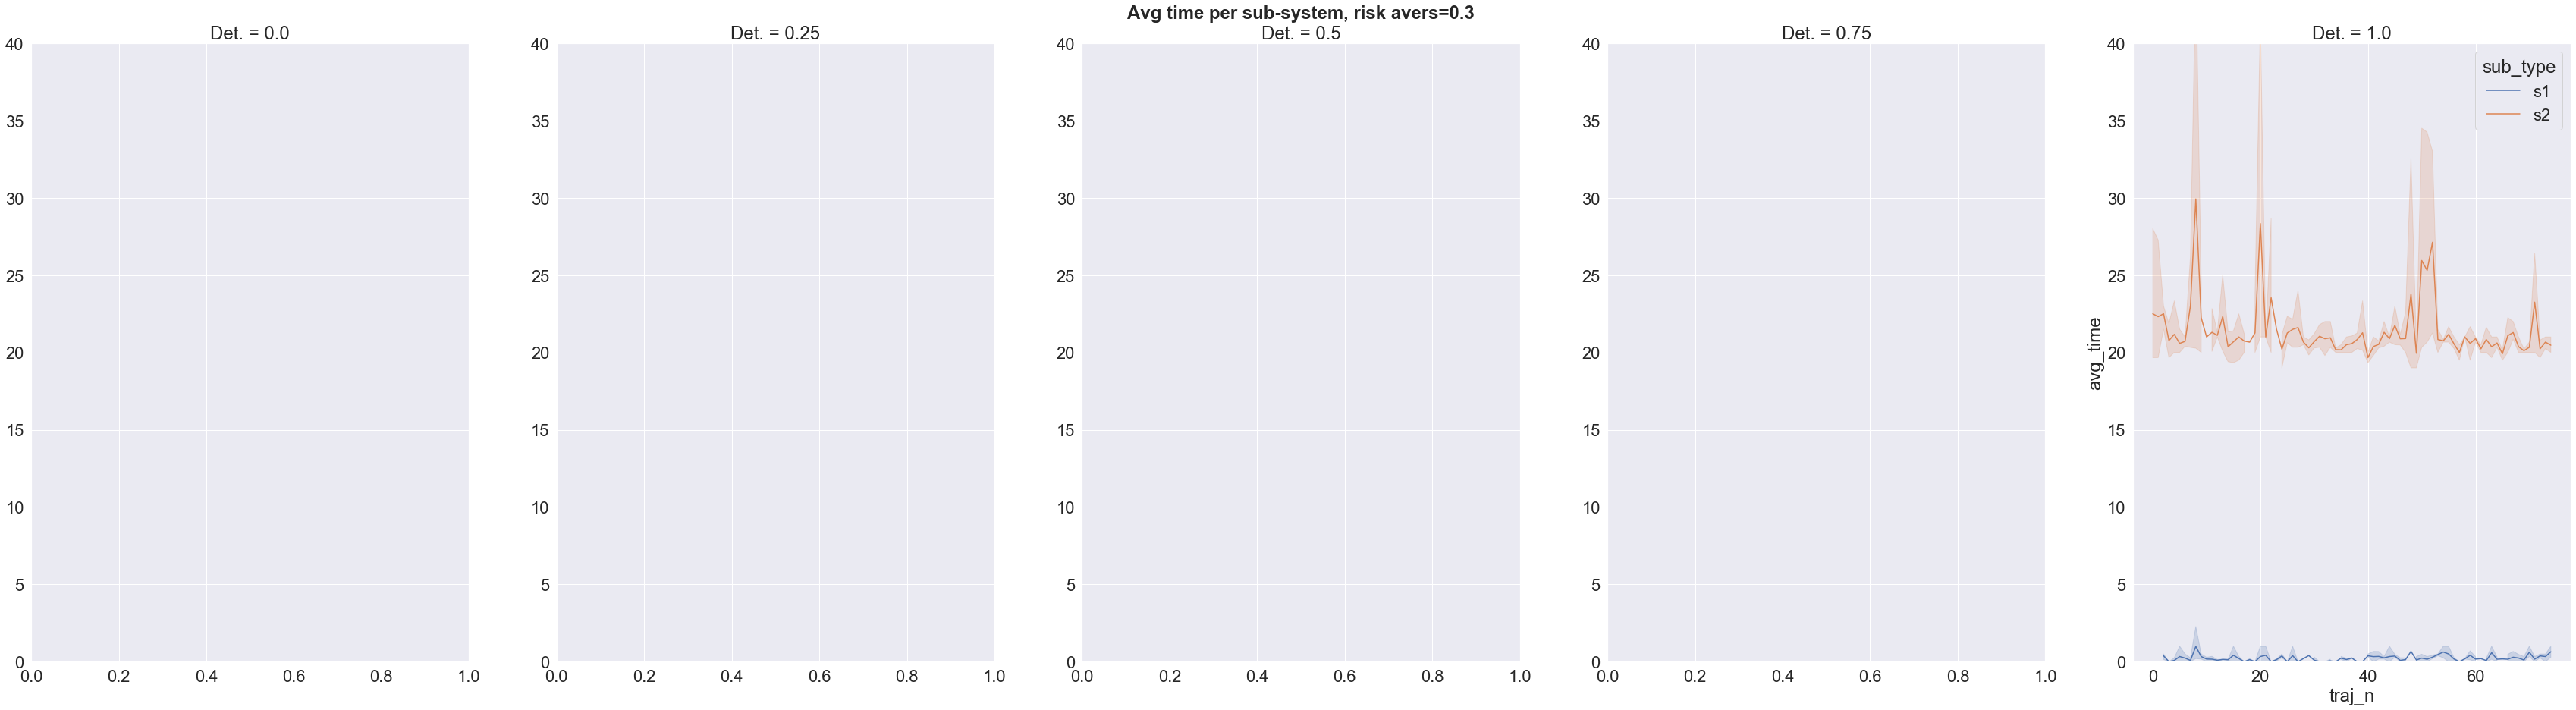

In [20]:
x='traj_n'
y='avg_time'
filename = y+'_time'
title="Avg time per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True, max_label=40)

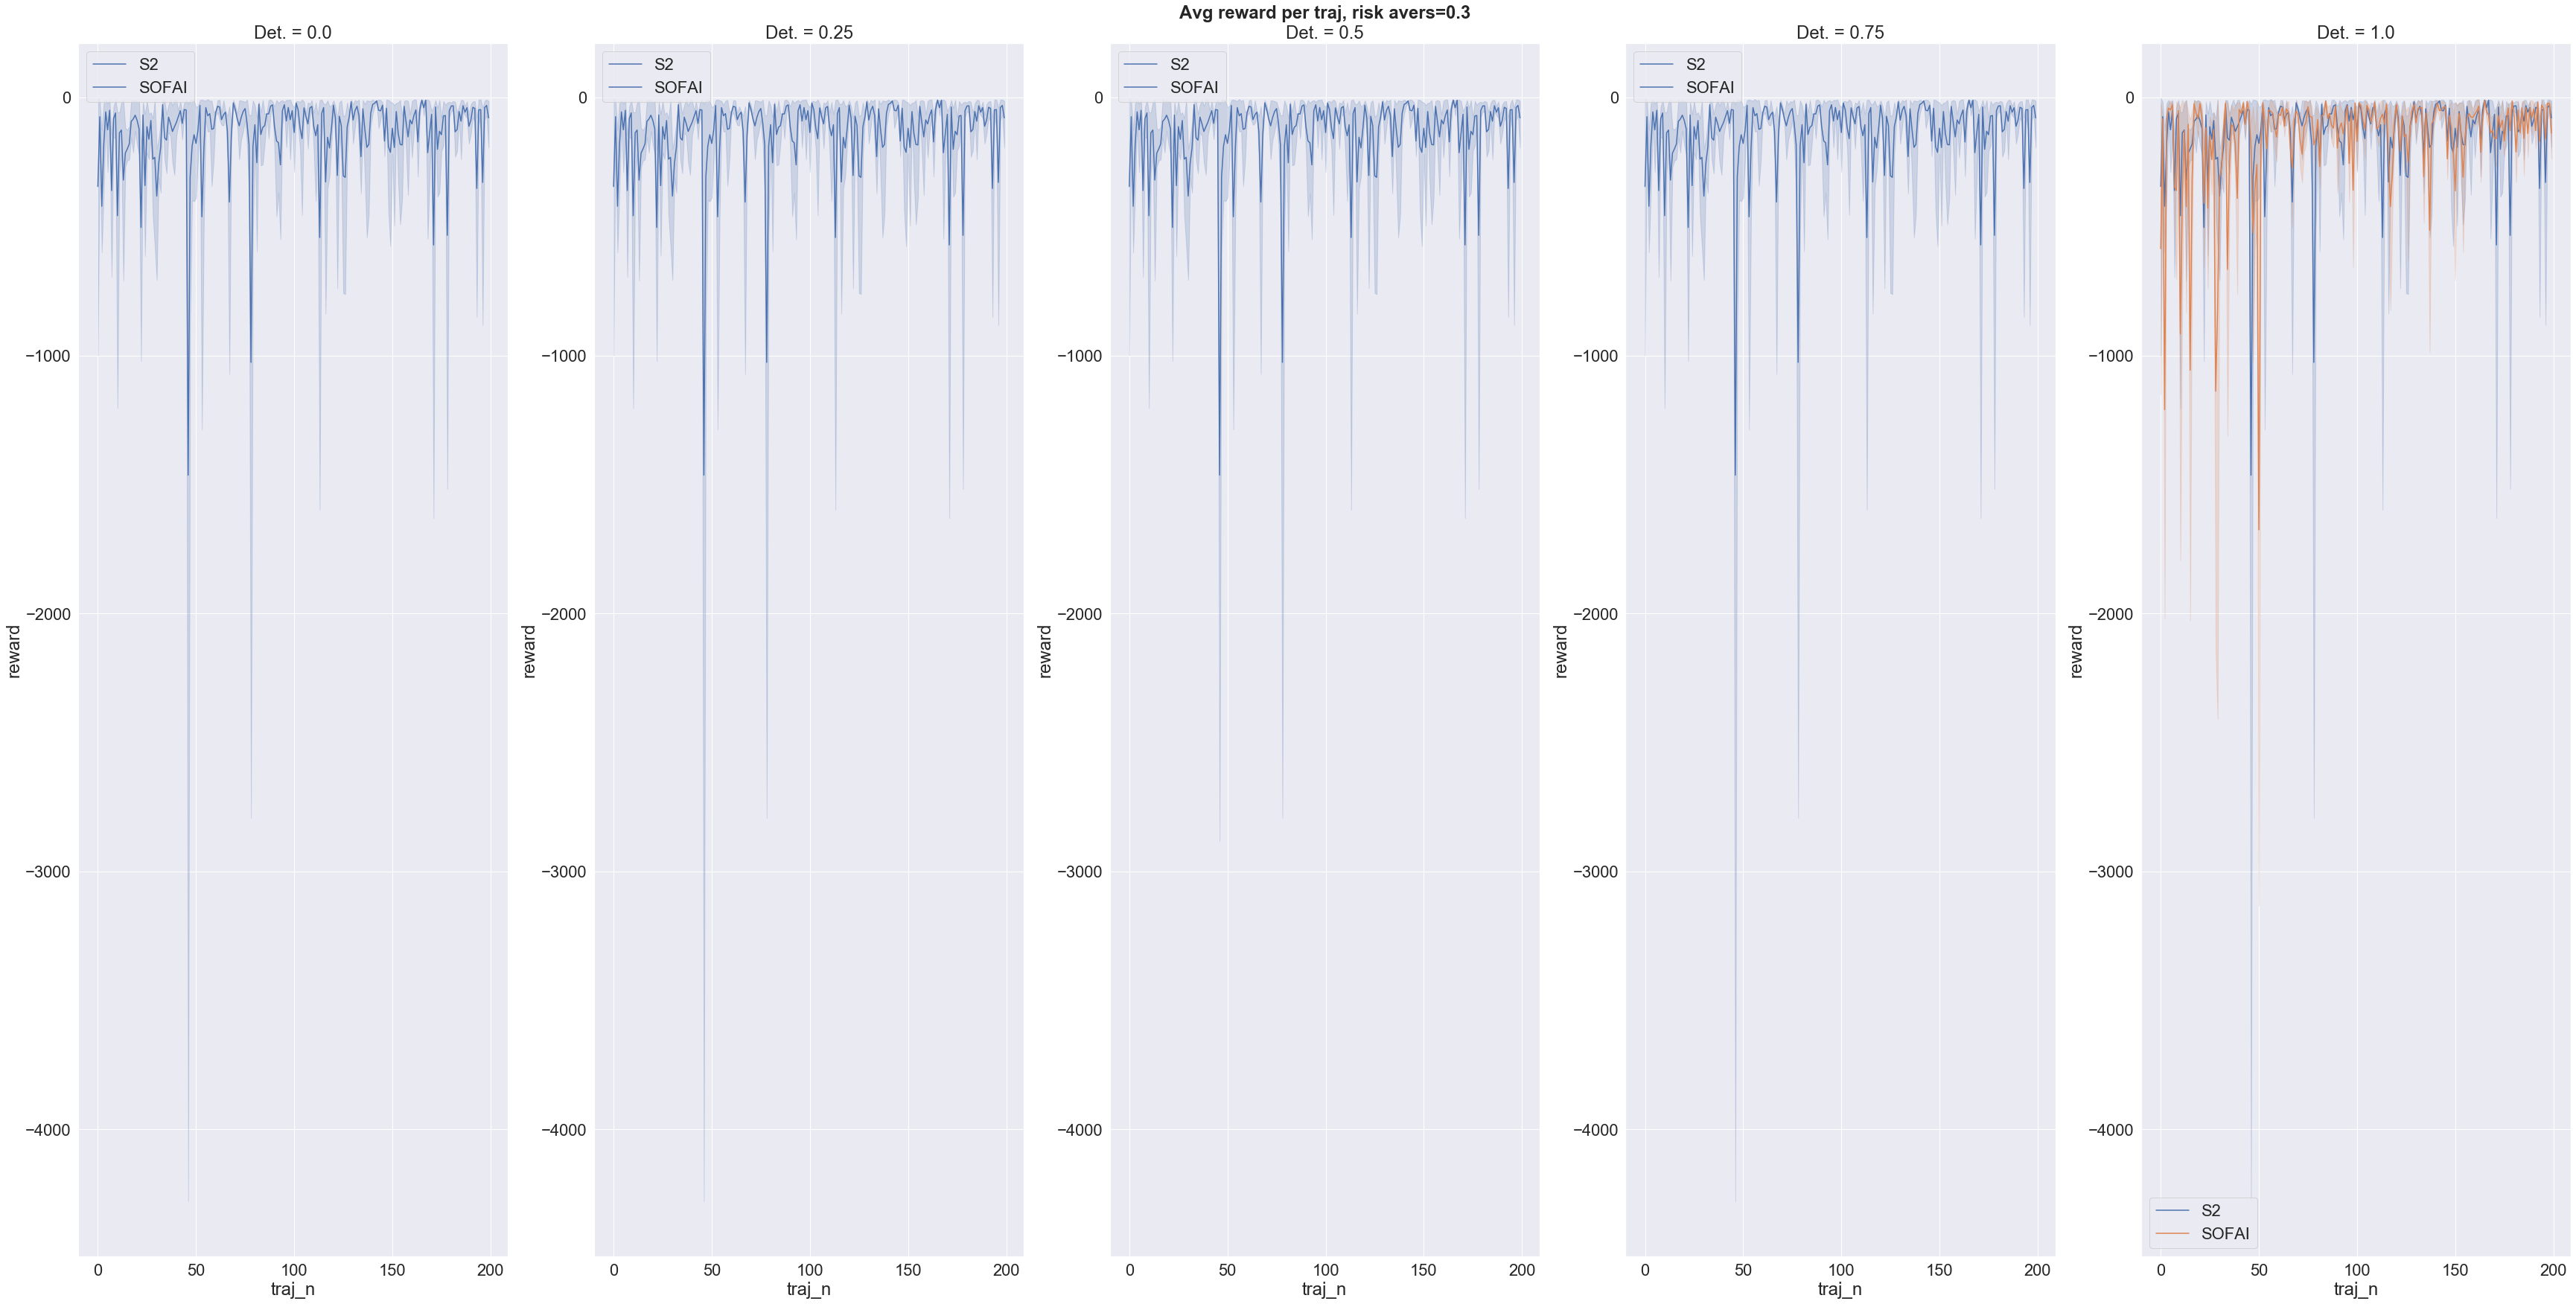

In [28]:
x='traj_n'
#y='perc_usage'
y='reward'
#y='time'


filename = 'avg_reward_per_traj'
title="Avg reward per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

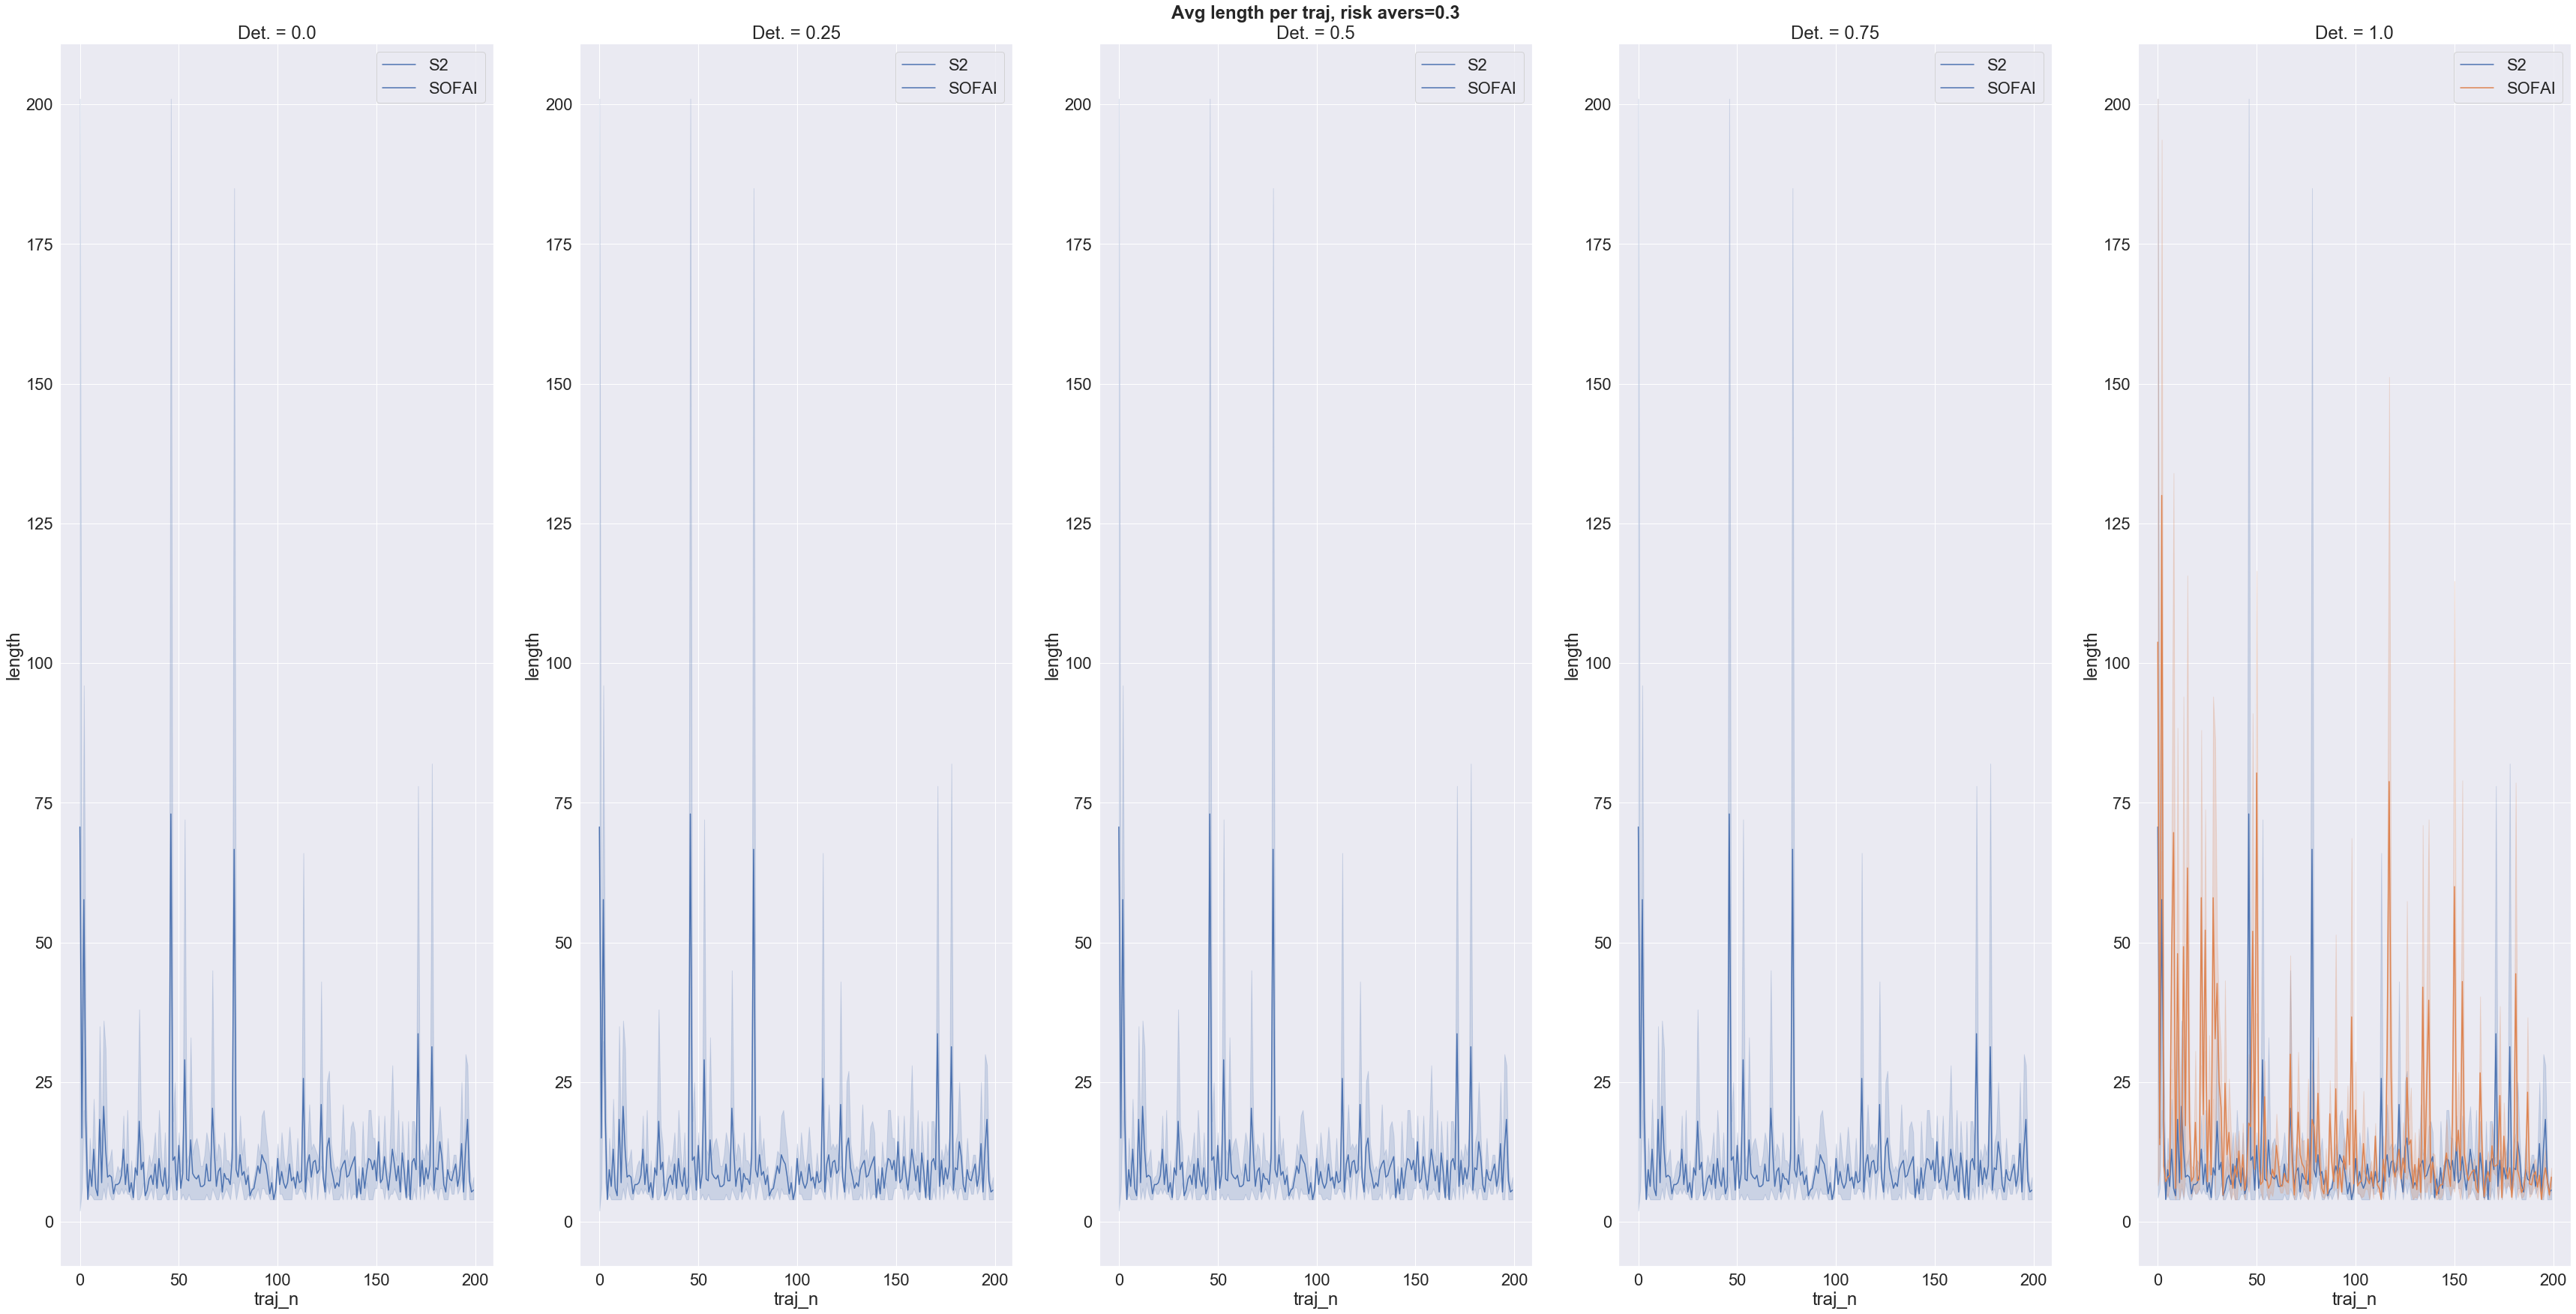

In [29]:
x='traj_n'
y='length'

filename = 'avg_length_per_traj'
title="Avg length per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

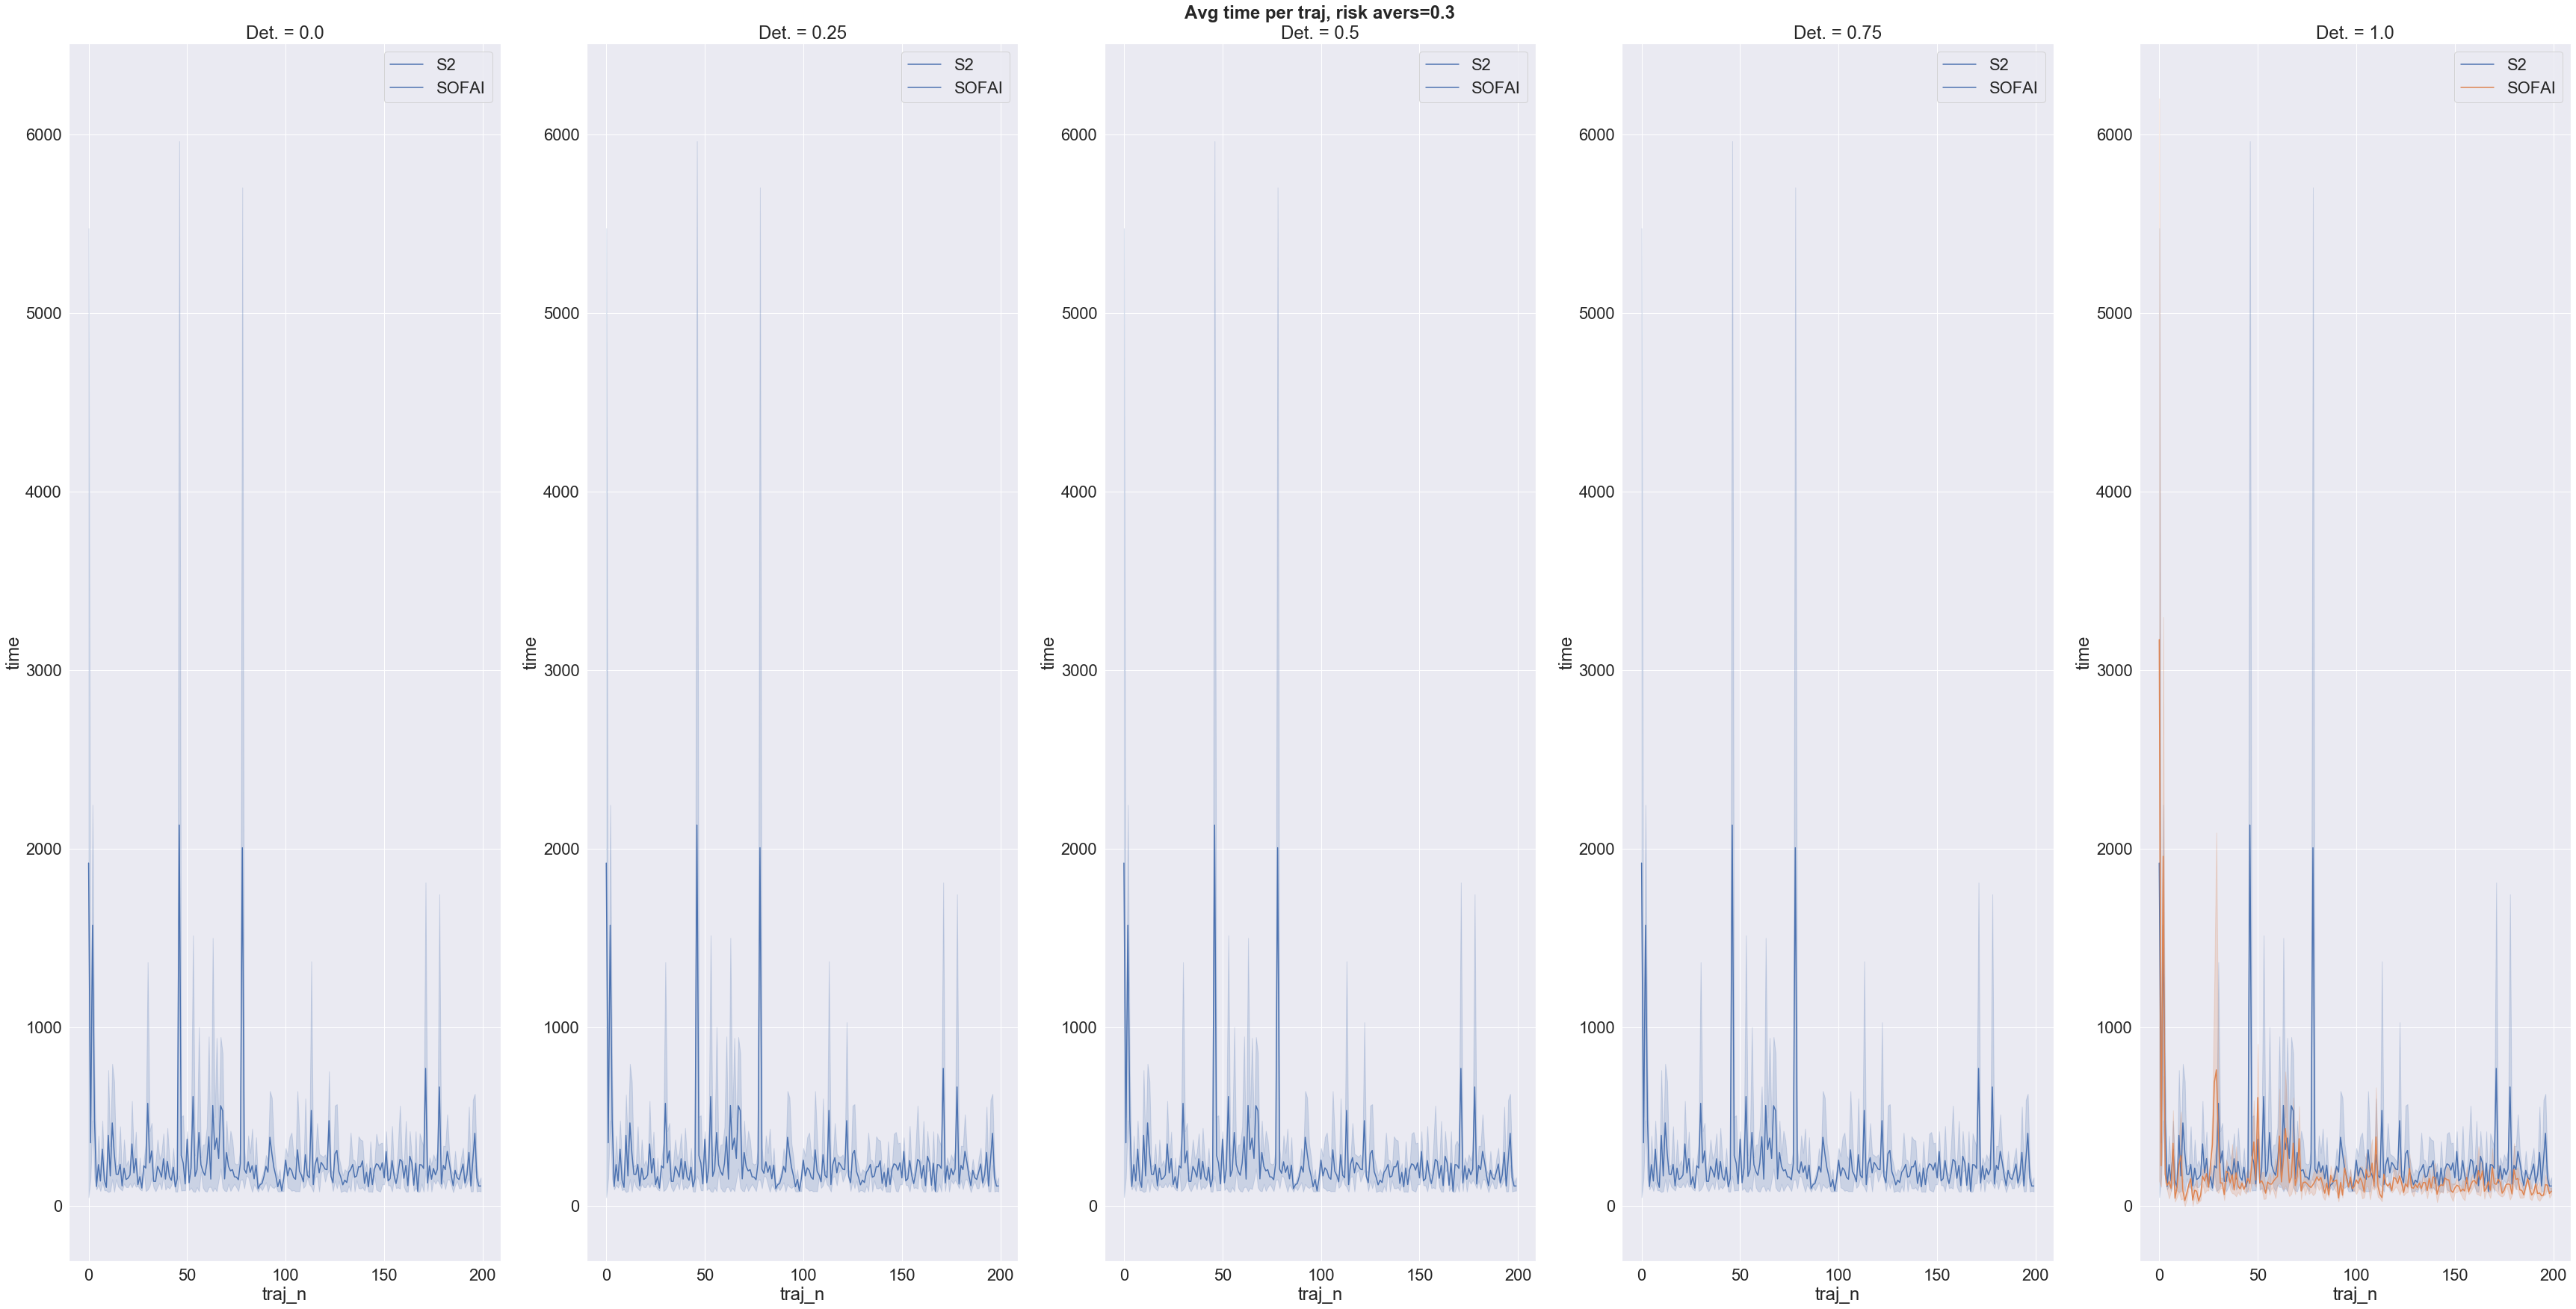

In [30]:
x='traj_n'
y='time'
filename = 'avg_time_withS1_per_traj'
title="Avg time per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

In [ ]:
#js_div = pd.read_csv('remaining_time/same_grid/risk0.8/jsdiv_myopic_nomyopic_risk_0.8.csv')
#temp_df = js_div.loc[((js_div['t3']==threshold3) & (js_div['t4']==threshold4)) | (js_div['type']=='s1_nb')]
temp_df =js_div

y='jsdiv'


fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)
g = sns.barplot(x='t3', y=y, hue="type", data=temp_df, palette="autumn", ci=95);

h, l = g.get_legend_handles_labels()
#labels=['S1',"SOFAI 01","SOFAI 10","SOFAI 02"]
#g.legend(h, labels)


plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel("t3")
plt.ylabel("JS div")
plt.title("JS Divergence")
plt.show()
fig.savefig(f"avg_js_dist.pdf", bbox_inches = 'tight') 

In [ ]:
x='traj_n'
y='viol_constr'
filename = 'avg_viol_aggregated_per_traj'
title="Avg viol per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, dropna=True)

In [ ]:
len(demo_list)

In [ ]:
mca_agents[4].modelSelf.grid.world.state_index_to_point(26)

In [ ]:
temp_dictionary = demo_list[-3].__dict__

In [ ]:
mca_agents[4].trajectory_stat[2]

In [ ]:
mca_agents[4].modelSelf.trajectories[:]

In [ ]:
r[4]

In [ ]:
blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)


In [ ]:
n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=True)

In [ ]:
print(mca_agents[4].modelSelf.getReward(26,1))
print(mca_agents[4].modelSelf.getRewardS2(26, maxLike=False, verbose=True))

In [ ]:
mca_agents[4].modelSelf.trajectories[0].transitions()[-1][2]

In [ ]:
mca_agents[4].modelSelf.ntra_per_transition[8,2,1]

In [ ]:
action = 1
print(sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print((list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys())))

for action in range(6):
    print(sum(np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys()))*np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))/sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print(mca_agents[4].modelSelf.ntra_per_stateAction_s2[(8, 2)])
print(mca_agents[4].modelSelf.ntra_per_stateAction[(8, 2)])

In [ ]:
#np.where(np.array(list(mca_agents[4].modelSelf.prob_s2[8,1,1,].values()))==11)
sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].keys()))/sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].values()))

In [ ]:
r = mca_agents[4].reflect(0.1)
print(sum(r[3]))
print(f"Temp: {mca_agents[4].temperature}")

In [ ]:
values_new = []
values = []
values_s2 = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    values_s2.append(-sum(mca_s2.action_reward[i])*sum(mca_s2.time_stat[i]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

In [ ]:
print(f"Temp: {mca_agents[4].temperature}")
threshold_delta = -0.0
compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)
#print(Trajectory(compare_traj[0]))

epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        #print(f"prima:{origTraj[transition]}")
        origTraj[transition] += 1
        #print(f"dopo:{origTraj[transition]}\n")
        
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))



distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
print(f"improvements {r[3]}")
values_new = []
values = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)


size = mca_agents[4].modelSelf.grid.world.size
epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        origTraj[transition] += 1	
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))

distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_s2, label="S2")
plt.plot(values, label="Old")
plt.legend()

In [ ]:
for index, transition in enumerate(l.transitions()):
    print(index)

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
compare_traj

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[0:50])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]]

In [ ]:
i = 4
mca_agents[4].modelSelf.trajectories[i]

In [ ]:
mca_agents[3].modelSelf.trajectories[i]

In [ ]:
mca_agents[4].trajectory_stat[i]

In [ ]:
mca_agents[3].trajectory_stat[i]

In [ ]:
sum(map(sum,mca_agents[3].action_reward))

In [ ]:
sum(map(sum,mca_agents[4].action_reward))

In [ ]:
mca_agents[4].s1.count_random

In [ ]:
sum(np.reshape(newtraj, (-1,)))

In [ ]:
r[3]

In [ ]:
mca_s2.modelSelf.getM()

In [ ]:
mca_agents[4].modelSelf.getAvgPartialReward(63)

In [ ]:
for row in np.array(mca_agents[4].thresholds_stat):
    for action in row:
        print(action[1])

In [1]:
df

NameError: name 'df' is not defined